# Markov Chains and Tumor Heterogeneity (v2: with a drug-holiday control)

**Overall premise:** You are a doctor and have a patient come to you with lung cancer. You sequence their tumor to try to understand what you are dealing with: you figure out what the composition of the tumor is, in terms of "cellular *states*". Out of the 100 cells you sequence, 50 of them have "type 1" identity, and 50 of them are "type 2" identity. You know that you have a drug to target type 1 cells, but that very drug also makes type 2 cells more resistant (i.e. grow more aggressively). Similarly, you have a drug that treats type 2 cells on their own, but don't know how it will affect a mixed tumor like the patient you see. What strategy should you use to help the patient? This is called **precision medicine** or **personalized medicine**: getting information about an individual patient and using a pre-built model on their own data to make predictions about their future under different drug treatments. 


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

One thing computational biologists would like to do is to look at tumors over time and see how cells transition between states (also called phenotypes). In real life, the experiments to track tumor cells over time generally require a few things:
1. Patients are not always biopsied multiple times, so instead, we use mice or other animal models, or **look at patient cells in a test tube** (*ex vivo* experiments). The following data is similar to what we would get if we did experiments on patient cells in test tubes.
2. The same cell can't be experimented on twice; the measurement of the cell's properties destroy it. Instead, we add a little **tag** onto cells and let them divide to make lots of cells with the same tag. Then we can take some of the cells in the first timepoint and some in another timepoint (often after a drug), and match up the ones with the same label. This means that real data is much messier; one tag in timepoint 1 could match up with several tags in timepoint 2 (or none at all, if that cell and its descendants all died). In this lab, we will assume one tagged cell in timepoint 1 matches up with no more than one in timepoint 2. 

## The lab goal: 
>**Simulate the patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:

1. **Decide the states.** Use K-means to cluster (simulated) sequencing data into states.
   
2. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
3. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
4. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
5. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


**The control experiment (a drug holiday).** A third culture got **no drug**
for one cycle (`experiment == "untreated"`). It shows what cells do during a
break in treatment: do they keep growing, die, or change state? You will use
it in Part 7. Until then, build everything from the two drug experiments as
before.

## 1. Setup

In [1]:
# !pip install umap-learn 

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

import umap   

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
cells = pd.read_csv("./cells_with_holiday.csv")
GENES = list(cells.columns[4:])

print(cells.shape)
print(cells.groupby(["experiment", "timepoint"]).size())
cells.head()

(14905, 64)
experiment   timepoint
docetaxel    A            3000
             B            1642
osimertinib  A            3000
             B            1419
untreated    A            3000
             B            2844
dtype: int64


,cell_id,experiment,timepoint,lineage_tag,CCND1,CDK6,MYC,E2F1,CDT1,PCNA,...,ISG15,IFIT1,IFIT3,MX1,OAS1,RPL13,RPS19,RPS27A,RPL32,RPS12
0,cell_o_00000,osimertinib,A,tago-02305,11,9,4,5,5,3,...,3,1,0,0,1,7,7,7,4,2
1,cell_o_00001,osimertinib,B,tago-01560,2,3,0,0,5,2,...,2,3,2,0,1,11,18,18,34,20
2,cell_o_00002,osimertinib,A,tago-02253,3,6,16,12,4,5,...,2,1,2,0,0,8,2,3,6,8
3,cell_o_00003,osimertinib,A,tago-01478,1,2,0,0,2,9,...,2,2,0,1,2,4,9,14,7,3
4,cell_o_00004,osimertinib,A,tago-02626,15,20,34,22,18,5,...,0,0,0,0,7,8,8,9,7,4


Each row is one cell. `experiment` is which drug the culture got, `timepoint` is `A` (before) or `B` (after one cycle), `lineage_tag` is the barcode (matching 2 cells between A and B), and the remaining 60 columns are counts of RNA molecules per gene.

<div class='alert alert-info'>
<b>Before you go on:</b> why are there fewer cells at time point B than at A?
</div>

*Answer the question above.*

## 1 · Decide the states

A Markov chain needs a **state space**: the finite list of values the process can take. Some computational biology tools consider each cell to be it's own state, so the state space is as big as your sample. You should have a good idea by now why that might not be the best idea.

Instead, we'll consider how to group the cells. There is a standard single-cell recipe, which is given to you below:

1. **Normalize** each cell to the same total count (cells are sequenced to different depths), then take `log1p`.
2. **PCA** on the normalized RNA counts, which are a measure of cell identity (phenotype) 
3. **Cluster** in PCA space with k-means.
4. **UMAP** to 2-D, *only for looking at*. UMAP distorts distances, so cluster in PCA space and draw in UMAP space.

**We embed every cell from both time points and both drugs together**, so that "cluster 2" means the same kind of cell everywhere. If you clustered each time point separately, the labels would not line up and you could not count transitions.

In [3]:
X = cells[GENES].to_numpy(dtype=float)
X = np.log1p(X / X.sum(axis=1, keepdims=True) * 1e4)   # normalize, log
X = (X - X.mean(axis=0)) / X.std(axis=0)               # standardize each gene

pcs = PCA(n_components=10, random_state=0).fit_transform(X)
emb = umap.UMAP(random_state=0).fit_transform(pcs)  
cells["x"], cells["y"] = emb[:, 0], emb[:, 1]

/opt/anaconda3/envs/uu/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Now cluster. `K` is the number of states you believe are in the data. After trying a few values for K and looking at the PCA and UMAP, you will notice that K=7 or 8 is a good fit.

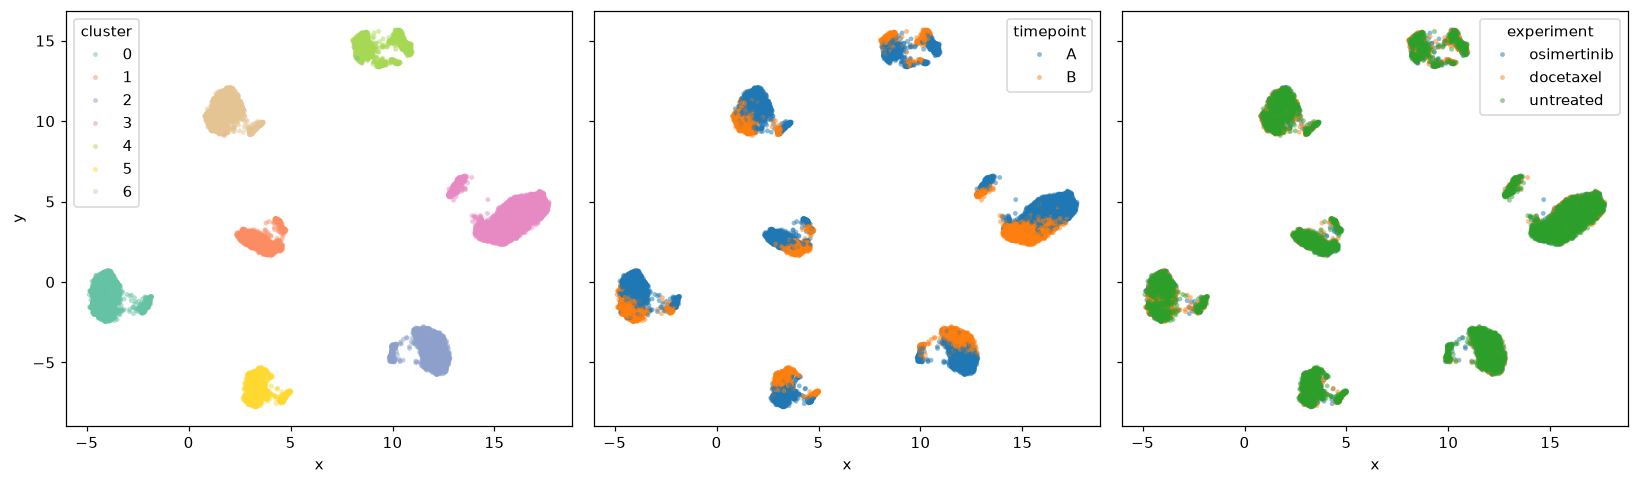

In [4]:
# Run KMeans' fit_predict method on pcs, and then plot using UMAP
# Do the clusters separate well?
import seaborn as sns
K = 7
cells["cluster"] = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(pcs)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "x", y ="y", hue = "cluster", ax = axes[0], palette = "Set2", s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "x", y ="y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "x", y ="y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

In [5]:
pd.crosstab([cells.experiment, cells.timepoint], cells.cluster)

cluster                  0    1    2    3    4    5    6
experiment  timepoint                                   
docetaxel   A          429  311  448  773  294  298  447
            B          330   27  140  333  253  112  447
osimertinib A          455  279  454  751  312  280  469
            B          417  279   78  212  285   66   82
untreated   A          440  307  441  737  290  331  454
            B          209  251  595  932  159  451  247

**Look at the table.** Compare time point A and time point B for each drug.
Which states grew and which shrank? Can you already tell, from these rows
alone, *where* the cells that left state S-G1 went?

You can't: the table gives the two marginal distributions, not the
transitions. Many different transition patterns produce the same before/after
totals. That is what the lineage tags are for.

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [6]:
osi = cells[cells["experiment"] == "osimertinib"]


In [7]:
at_A = osi[osi.timepoint == "A"][["lineage_tag", "cluster"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "cluster"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))

In [8]:
pairs

,lineage_tag,cluster_A,cluster_B
0,tago-02305,3,NaN
1,tago-02253,3,NaN
2,tago-01478,2,4.0
3,tago-02626,3,0.0
4,tago-01487,0,0.0
...,...,...,...
2995,tago-00418,3,NaN
2996,tago-01409,5,NaN
2997,tago-01170,0,0.0
2998,tago-01753,0,2.0


In [9]:
pairs["cluster_B"] = pairs["cluster_B"].fillna("cleared")


In [10]:
counts = (pd.crosstab(pairs.cluster_A, pairs.cluster_B))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [11]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


cluster_B,0.0,1.0,2.0,3.0,4.0,5.0,6.0,cleared
cluster_A,,,,,,,,
0,160,0,11,47,75,8,0,154
1,0,279,0,0,0,0,0,0
2,38,0,23,27,16,17,0,333
3,154,0,17,91,41,11,0,437
4,31,0,0,19,153,0,0,109
5,20,0,13,8,0,20,0,219
6,14,0,14,20,0,10,82,329


estimated transition matrix (osimertinib, one cycle):


cluster_B,0.0,1.0,2.0,3.0,4.0,5.0,6.0,cleared
cluster_A,,,,,,,,
0,0.352,0.0,0.024,0.103,0.165,0.018,0.000,0.338
1,0.000,1.0,0.000,0.000,0.000,0.000,0.000,0.000
2,0.084,0.0,0.051,0.059,0.035,0.037,0.000,0.733
3,0.205,0.0,0.023,0.121,0.055,0.015,0.000,0.582
4,0.099,0.0,0.000,0.061,0.490,0.000,0.000,0.349
5,0.071,0.0,0.046,0.029,0.000,0.071,0.000,0.782
6,0.030,0.0,0.030,0.043,0.000,0.021,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [12]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [13]:
STATES = sorted(cells["cluster"].unique())
OUTCOMES = STATES + ["cleared"]

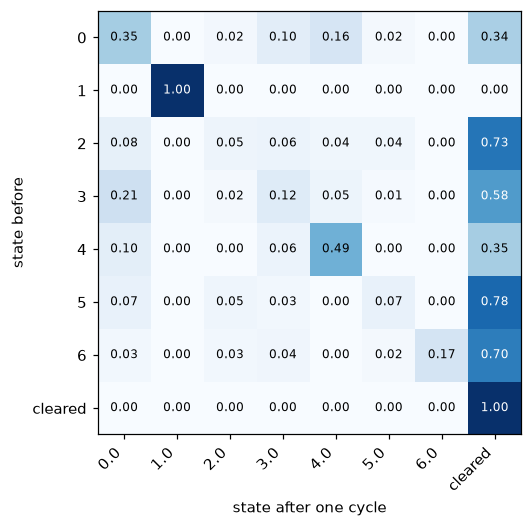

In [14]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, is any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

*Answer here.*

## 3. Simulate a tumor composed on 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state 0?" Equivalently, "what happens to a tumor made entirely of cells in state 0?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [15]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [16]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis(0, P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

In [17]:
traj = evolve(basis(0, P_hat), P_hat, 10)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,0,1,2,3,4,5,6,cleared
0,1.000,0.0,0.000,0.000,0.000,0.000,0.0,0.000
1,0.352,0.0,0.024,0.103,0.165,0.018,0.0,0.338
2,0.164,0.0,0.013,0.061,0.145,0.010,0.0,0.607
3,0.087,0.0,0.006,0.034,0.102,0.005,0.0,0.766
4,0.048,0.0,0.003,0.020,0.066,0.003,0.0,0.859
5,0.028,0.0,0.002,0.012,0.042,0.001,0.0,0.915
6,0.017,0.0,0.001,0.007,0.026,0.001,0.0,0.948
7,0.010,0.0,0.001,0.004,0.016,0.000,0.0,0.969
8,0.006,0.0,0.000,0.003,0.010,0.000,0.0,0.981
9,0.004,0.0,0.000,0.002,0.006,0.000,0.0,0.988


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

0
1
2
3
4
5
6


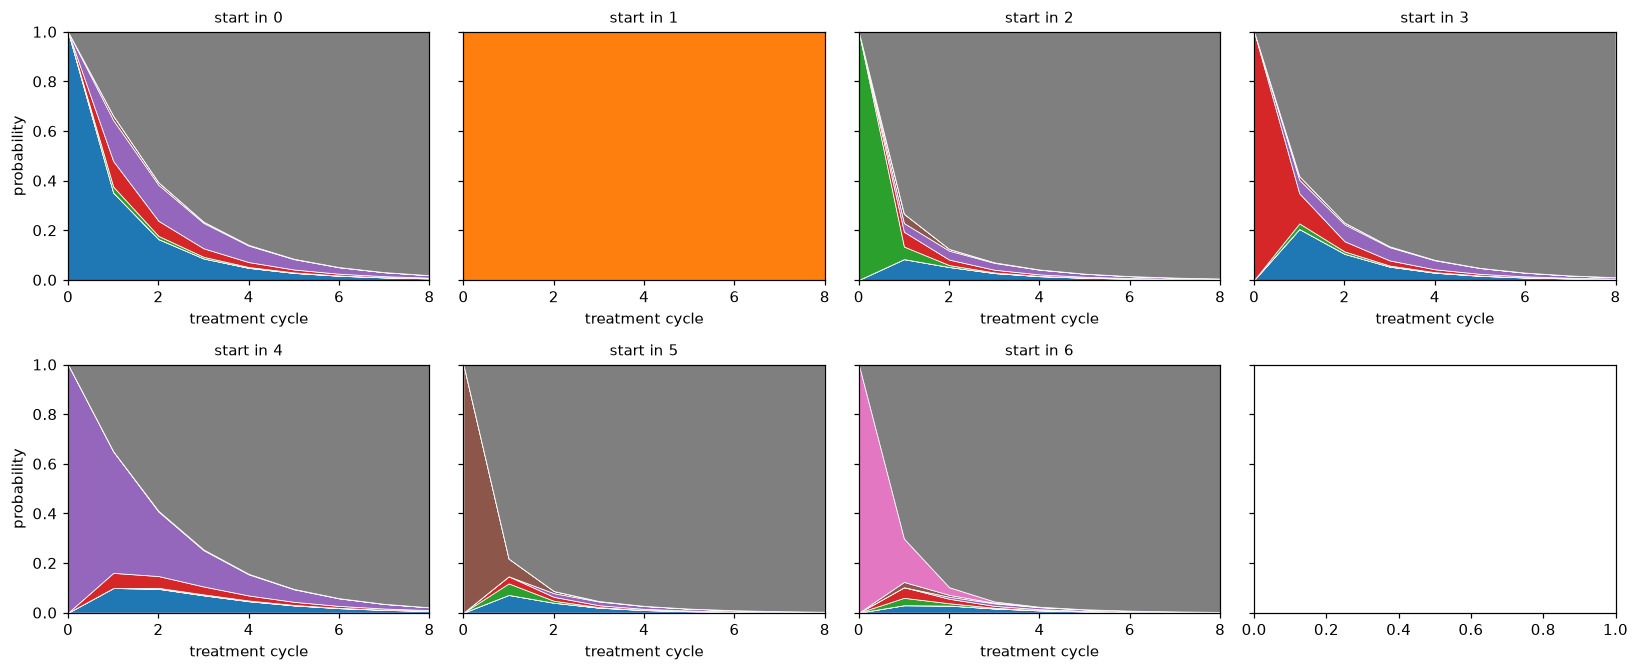

fraction alive after 3 cycles: {np.int32(0): np.float64(0.234), np.int32(1): np.float64(1.0), np.int32(2): np.float64(0.071), np.int32(3): np.float64(0.135), np.int32(4): np.float64(0.254), np.int32(5): np.float64(0.047), np.int32(6): np.float64(0.045), 'cleared': np.float64(0.0)}


In [18]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T,
                 labels=STATES, edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    print(s)
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 3)[-1, -1] for s in OUTCOMES}
print("fraction alive after 3 cycles:", {s: round(v, 3) for s, v in alive3.items()})

**Read the seven panels.**

- Which starting states does osimertinib eliminate (all probability ends in `cleared`)? Which one survives?
- Which starting state results in a tumor that lasts the longest?
- Which starting state results in the highest proportion of alive cells after three cycles?



measured mix: {np.int32(0): np.float64(0.152), np.int32(1): np.float64(0.093), np.int32(2): np.float64(0.151), np.int32(3): np.float64(0.25), np.int32(4): np.float64(0.104), np.int32(5): np.float64(0.093), np.int32(6): np.float64(0.156)}


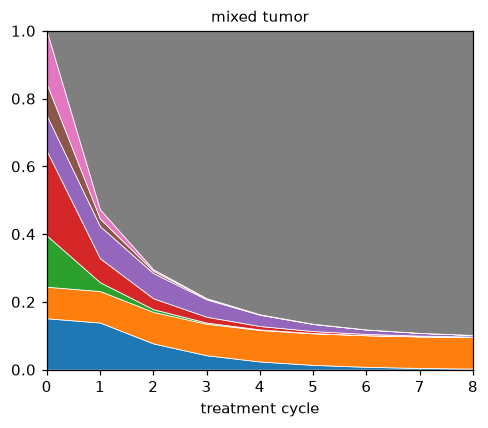

In [19]:
start_A = osi[osi.timepoint == "A"].cluster.value_counts(normalize=True)
pi_mix = np.append(start_A.reindex(STATES).to_numpy(), 0.0)
print("measured mix:", dict(zip(STATES, pi_mix.round(3))))

traj_mix = evolve(pi_mix, P_hat, N_CYCLES)
fig, ax = plt.subplots(figsize=(5, 4))
plot_trajectory(traj_mix, ax, "mixed tumor")
plt.show()

**Read the three panels.**


### A mixed tumor

The experiment at time point A was a mix of all seven states. Use its measured composition as $\pi_0$ and compare it with a tumor made only of 1 cell type.

## 4 · Simulate random walks

The matrix calculation tracks *probabilities*. A random walk tracks *one cell*:
at each cycle, draw a random number and use the current row of $P$ to pick the
next state.

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the
**inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$
and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [20]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    u = rng.random()
    return int(np.searchsorted(np.cumsum(P[i]), u, side="right"))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [21]:
import seaborn as sns

# From here on we use the matrix as a numpy array (rows and columns in OUTCOMES order).
P = P_hat.to_numpy()
N_CYCLES = 15   # a longer course from here on (Part 3 used 8)

# One colour per cluster, matching the UMAP plot (Set2), and gray for "cleared".
STATE_COLORS = dict(zip(STATES, sns.color_palette("Set2", len(STATES))))
STATE_COLORS["cleared"] = "#8a8984"

# The biggest cluster at time point A: we use it as an example starting state.
BIG = start_A.idxmax()
start = OUTCOMES.index(BIG)
for _ in range(5):
    print(" -> ".join(str(OUTCOMES[i]) for i in random_walk(start, P, 8, rng)))

3 -> 3 -> 0 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
3 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
3 -> 4 -> 4 -> 4 -> cleared -> cleared -> cleared -> cleared -> cleared
3 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
3 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

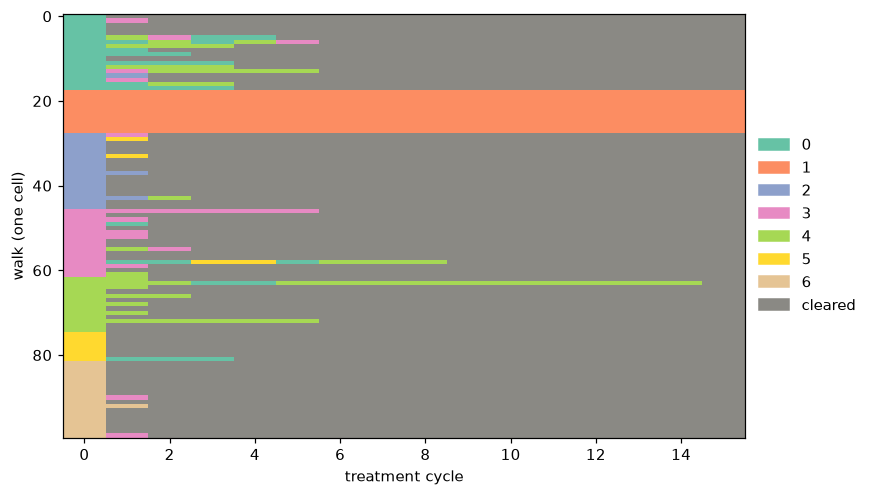

In [22]:
N_WALKS = 100
starts = np.searchsorted(np.cumsum(pi_mix), rng.random(N_WALKS), side="right")
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [23]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

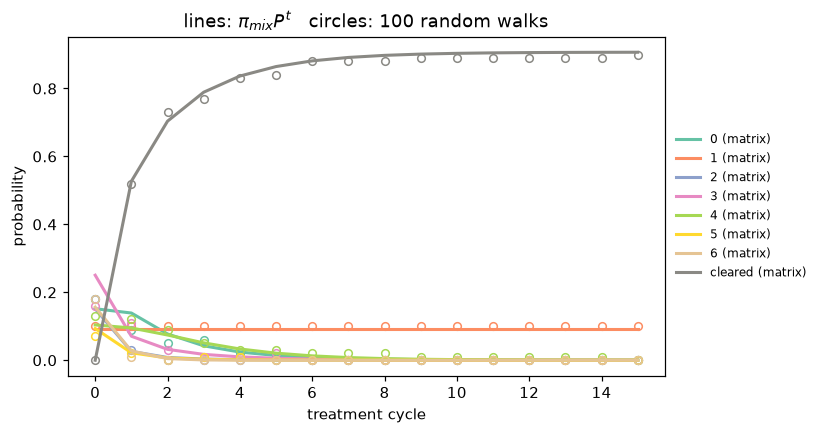

In [24]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 4))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

**Questions.**

1. Re-run the last three cells with `N_WALKS = 10` and `N_WALKS = 10_000`. How
   does the gap between the circles and the lines change? Which result from
   earlier in the course predicts this?
2. Which method would you use to answer "what fraction of cells are alive
   after 15 cycles?" Which would you use to answer "how many cycles does a
   typical cell from the biggest cluster survive?" Why?

### Simulate whole tumors

A tumor is many cells. In our model each cell follows the chain on its own,
independently of the others, so **a tumor of $N$ cells is $N$ random walks**.
The tumor is **cured** if every one of its cells ends in `cleared`, and it
**relapses** if even one cell survives.

Simulate many tumors from each starting composition and estimate the
probability of each outcome.

**Which cluster can osimertinib not kill?** That was the question at the end
of Part 2: the cluster whose row of `P_hat` keeps almost all of its cells in
place. Find it from the matrix, and call it `R_OSI`.

In [25]:
stay = pd.Series(np.diag(P)[:len(STATES)], index=STATES)
print("probability of staying in the same cluster for one cycle of osimertinib:")
print(stay.round(3))
R_OSI = stay.idxmax()
print("cluster osimertinib can't kill: R_OSI =", R_OSI)

probability of staying in the same cluster for one cycle of osimertinib:
0    0.352
1    1.000
2    0.051
3    0.121
4    0.490
5    0.071
6    0.175
dtype: float64
cluster osimertinib can't kill: R_OSI = 1


In [26]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = np.searchsorted(np.cumsum(pi0), rng.random(n_cells), side="right")
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

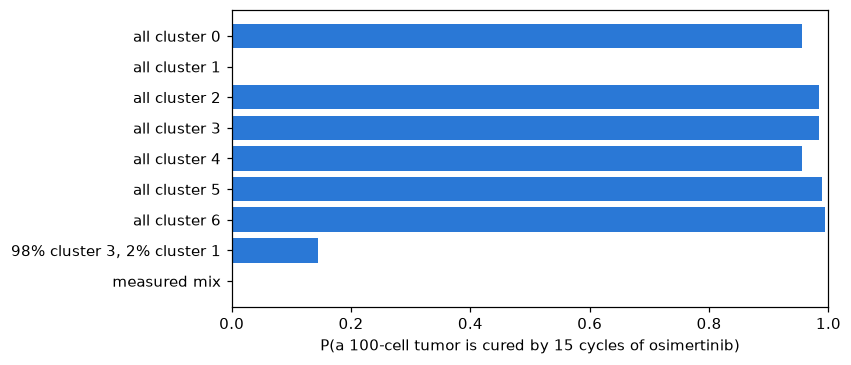

,P(cured),mean surviving cells,share of survivors in cluster 1
start,,,
all cluster 0,0.955,0.045,0.000
all cluster 1,0.000,100.000,1.000
all cluster 2,0.985,0.015,0.000
all cluster 3,0.985,0.015,0.000
all cluster 4,0.955,0.045,0.000
all cluster 5,0.990,0.010,0.000
all cluster 6,0.995,0.005,0.000
"98% cluster 3, 2% cluster 1",0.145,2.015,0.993
measured mix,0.000,9.265,0.997


In [27]:
N_CELLS, N_TUMORS = 100, 200
scenarios = {f"all cluster {s}": basis(s, P_hat) for s in STATES}
scenarios[f"98% cluster {BIG}, 2% cluster {R_OSI}"] = 0.98 * basis(BIG, P_hat) + 0.02 * basis(R_OSI, P_hat)
scenarios["measured mix"] = pi_mix
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P, N_CELLS, N_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 f"share of survivors in cluster {R_OSI}":
                     (finals == OUTCOMES.index(R_OSI)).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_CYCLES} cycles of osimertinib)")
plt.show()
results.round(3)

**Questions.**

1. The 98% / 2% tumor has only about 2 cells from `R_OSI` out of 100, yet
   it is rarely cured. Work out the probability that a 100-cell tumor drawn
   from that mix contains **no** `R_OSI` cell at all, and compare it with the
   simulation.
2. A real tumor has about $10^9$ cells. If one cell in a million is an `R_OSI`
   cell, what is the chance a tumor contains at least one?
3. The matrix calculation in Part 3 gives the *expected fraction* of cells
   alive. What does the tumor simulation tell you that the matrix calculation
   doesn't?

## 5 · Which tumors can osimertinib cure?

A tumor is a mixture, $\pi_0 = (w_0, \dots, w_6, 0)$ with the
weights summing to 1. The outcome we care about is the **fraction of the
original cells still alive** after $n$ cycles:

$$
a(\pi_0) \;=\; 1 - \big[\pi_0 P^{n}\big]_{\text{cleared}}.
$$

A tumor of $N$ cells has on average $N\,a(\pi_0)$ surviving cells. We call
the tumor **curable** if that is below 0.1 for $N = 100$ (then there is at
most a 10% chance that any cell survives).

In [28]:
def alive_fraction(pi0, P, n_cycles):
    '''Fraction of original cells not in "cleared" after n_cycles.'''
    return 1 - evolve(pi0, P, n_cycles)[-1, OUTCOMES.index("cleared")]

In [29]:
for s in STATES:
    a = alive_fraction(basis(s, P_hat), P, N_CYCLES)
    print(f"start in {s!s:>7}:  a = {a:.5f}   expected survivors of {N_CELLS} cells = {N_CELLS * a:.3f}")

start in       0:  a = 0.00059   expected survivors of 100 cells = 0.059
start in       1:  a = 1.00000   expected survivors of 100 cells = 100.000
start in       2:  a = 0.00017   expected survivors of 100 cells = 0.017
start in       3:  a = 0.00033   expected survivors of 100 cells = 0.033
start in       4:  a = 0.00067   expected survivors of 100 cells = 0.067
start in       5:  a = 0.00011   expected survivors of 100 cells = 0.011
start in       6:  a = 0.00009   expected survivors of 100 cells = 0.009


### Adding a few resistant cells

Start with a tumor made only of the biggest cluster (`BIG`) and replace a
fraction $w$ of its cells with `R_OSI` cells. Sweep $w$ from 0 to 5%.

**Predict the shape of the curve before you run it.** Straight? Curved? How
large can $w$ be before the tumor stops being curable?

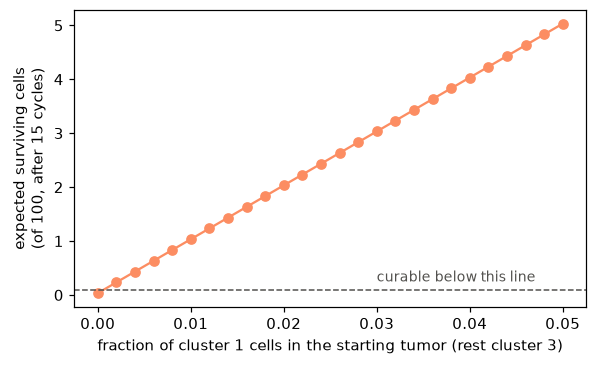

In [30]:
w = np.linspace(0, 0.05, 26)
surv = [N_CELLS * alive_fraction((1 - wi) * basis(BIG, P_hat) + wi * basis(R_OSI, P_hat), P, N_CYCLES) for wi in w]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(w, surv, "o-", color=STATE_COLORS[R_OSI])
ax.axhline(0.1, color="#52514e", ls="--", lw=1)
ax.text(0.03, 0.25, "curable below this line", color="#52514e", fontsize=9)
ax.set_xlabel(f"fraction of cluster {R_OSI} cells in the starting tumor (rest cluster {BIG})")
ax.set_ylabel(f"expected surviving cells\n(of {N_CELLS}, after {N_CYCLES} cycles)")
plt.show()

**Why is it a straight line?** Matrix multiplication is linear, so

$$
\big(w\,e_{R} + (1-w)\,e_{B}\big) P^n
\;=\; w\,\big(e_{R} P^n\big) + (1-w)\,\big(e_{B} P^n\big).
$$

where $e_R$ and $e_B$ are the basis vectors for `R_OSI` and `BIG`. The fate of a mixture is the same mixture of the fates of its basis vectors.
That is why we started with basis vectors: **the seven basis-vector outcomes
already determine the outcome of every possible tumor.**

### All seven states

Use that. Grid over all tumors in steps of 0.1 (8,008 compositions) and find
the ones osimertinib can cure.

In [31]:
a_basis = np.array([alive_fraction(basis(s, P_hat), P, N_CYCLES) for s in STATES])

grid = [(*w, 10 - sum(w)) for w in itertools.product(range(11), repeat=6) if sum(w) <= 10]
mixes = pd.DataFrame(grid, columns=STATES) / 10

mixes["survivors"] = N_CELLS * mixes[STATES].to_numpy() @ a_basis
curable = mixes[mixes.survivors < 0.1]

In [32]:
print(f"Osimertinib can cure {len(curable)} of {len(mixes)} tumor compositions.")
print("largest share of each state among the curable tumors:")
print(curable[STATES].max().round(2))

Osimertinib can cure 3003 of 8008 tumor compositions.
largest share of each state among the curable tumors:
0    1.0
1    0.0
2    1.0
3    1.0
4    1.0
5    1.0
6    1.0
dtype: float64


**Questions.**

1. Which state decides whether osimertinib can cure a tumor? Explain using
   `a_basis`.
2. Write down the inequality a tumor must satisfy to be curable, and explain
   why the curable tumors are cut out by a single flat boundary (a plane).
3. A curable tumor can contain all six other states, in any proportions. So
   it is not "having more than one state" that defeats osimertinib. What
   exactly is it?

## 6 · A second drug: docetaxel

The file has a second culture treated with **docetaxel**. Build its transition
matrix exactly as in Part 2, see which tumors *it* can cure, and then compare
three schedules for the mixed tumor we measured at time point A:

- osimertinib every cycle,
- docetaxel every cycle,
- alternate osimertinib, docetaxel, osimertinib, ….

For an alternating schedule, one *pair* of cycles multiplies by
$P_{osi} P_{doc}$.

In [33]:
def transition_matrix(cells, experiment):
    '''Square transition matrix for one experiment, as a DataFrame with rows and
    columns in OUTCOMES order (the same steps as Part 2).'''
    exp = cells[cells.experiment == experiment]
    at_A = exp[exp.timepoint == "A"][["lineage_tag", "cluster"]]
    at_B = exp[exp.timepoint == "B"][["lineage_tag", "cluster"]]
    pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pairs["cluster_B"] = pairs["cluster_B"].fillna("cleared")
    counts = (pd.crosstab(pairs.cluster_A, pairs.cluster_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    P_exp = counts.div(counts.sum(axis=1), axis=0)
    P_exp.loc["cleared"] = [1 if c == "cleared" else 0 for c in P_exp.columns]
    return P_exp

Phat_osi = transition_matrix(cells, "osimertinib")
Phat_doc = transition_matrix(cells, "docetaxel")
P_osi, P_doc = Phat_osi.to_numpy(), Phat_doc.to_numpy()

R_DOC = STATES[int(np.argmax(np.diag(P_doc)[:len(STATES)]))]
print("cluster docetaxel can't kill: R_DOC =", R_DOC)
MATS = {"O": P_osi, "D": P_doc}

cluster docetaxel can't kill: R_DOC = 6


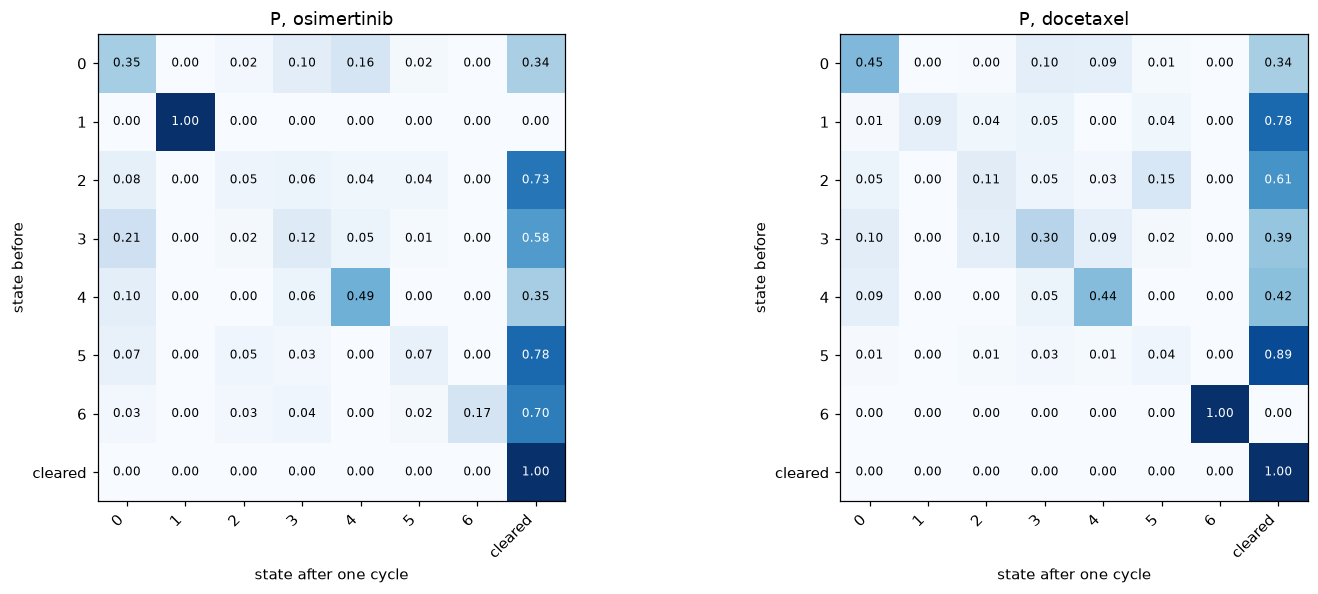

fraction alive after 3 cycles of docetaxel: {0: 0.251, 1: 0.034, 2: 0.068, 3: 0.189, 4: 0.204, 5: 0.023, 6: 1.0}


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
show_matrix(Phat_osi, "P, osimertinib", axes[0])
show_matrix(Phat_doc, "P, docetaxel", axes[1])
plt.tight_layout()
plt.show()

print("fraction alive after 3 cycles of docetaxel:",
      {int(s): round(float(alive_fraction(basis(s, P_hat), P_doc, 3)), 3) for s in STATES})

**Compare the sensitive states under docetaxel.** Docetaxel kills cells as
they divide. Which of the three sensitive states does it kill fastest, and
which does it spare for longest? Is that the same order as under osimertinib?

### Which tumors can each drug cure?

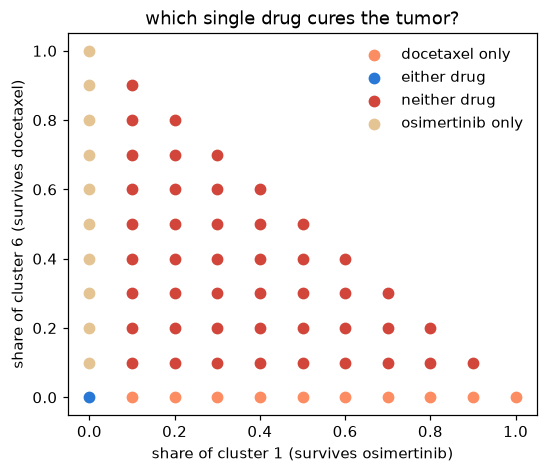

cured by
neither drug        3003
osimertinib only    2002
docetaxel only      2002
either drug         1001
Name: count, dtype: int64

In [35]:
def curable_by(P, n_cycles):
    '''True for each row of `mixes` that P can cure (expected survivors < 0.1).'''
    a = np.array([alive_fraction(basis(s, P_hat), P, n_cycles) for s in STATES])
    return N_CELLS * mixes[STATES].to_numpy() @ a < 0.1

c_osi, c_doc = curable_by(P_osi, N_CYCLES), curable_by(P_doc, N_CYCLES)
mixes["cured by"] = np.select([c_osi & c_doc, c_osi, c_doc],
                              ["either drug", "osimertinib only", "docetaxel only"], "neither drug")
CURE_COLORS = {"either drug": "#2a78d6", "osimertinib only": STATE_COLORS[R_DOC],
               "docetaxel only": STATE_COLORS[R_OSI], "neither drug": "#d1453b"}

pts = mixes[[R_OSI, R_DOC, "cured by"]].drop_duplicates()
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for label, sub in pts.groupby("cured by"):
    ax.scatter(sub[R_OSI], sub[R_DOC], s=45, color=CURE_COLORS[label], label=label)
ax.set_xlabel(f"share of cluster {R_OSI} (survives osimertinib)")
ax.set_ylabel(f"share of cluster {R_DOC} (survives docetaxel)")
ax.set_title("which single drug cures the tumor?")
ax.legend(frameon=False, loc="upper right")
plt.show()
mixes["cured by"].value_counts()

### Schedules for the mixed tumor

In [36]:
def run_schedule(pi0, schedule):
    '''schedule is a string like "OOOO" (osimertinib) or "ODOD"; return the final distribution.'''
    pi = np.asarray(pi0, dtype=float)
    for drug in schedule:
        pi = pi @ MATS[drug]
    return pi

for name, sched in [("osimertinib only", "O" * N_CYCLES), ("docetaxel only", "D" * N_CYCLES),
                    ("alternate", ("OD" * N_CYCLES)[:N_CYCLES])]:
    final = run_schedule(pi_mix, sched)
    resistant = final[OUTCOMES.index(R_OSI)] + final[OUTCOMES.index(R_DOC)]
    print(f"{name:>16}: alive = {1 - final[-1]:.5f}   resistant = {resistant:.5f}   "
          f"expected survivors of {N_CELLS} = {N_CELLS * (1 - final[-1]):.3f}")

osimertinib only: alive = 0.09329   resistant = 0.09300   expected survivors of 100 = 9.329
  docetaxel only: alive = 0.15655   resistant = 0.15633   expected survivors of 100 = 15.655
       alternate: alive = 0.00024   resistant = 0.00000   expected survivors of 100 = 0.024


**Questions.**

1. In the plot, which tumors can **neither** drug cure on its own? Describe
   them in one sentence.
2. Why does alternating cure the mixed tumor? Point to the specific entries
   of $P_{osi}$ and $P_{doc}$.
3. Is `CP` still an absorbing state of the two-cycle matrix $P_{osi} P_{doc}$?
   What does that imply for the long run?
4. *(Simulation.)* Re-run the tumor simulation from Part 4 for the mixed
   tumor with the alternating schedule. How often is a 100-cell tumor cured?
5. *(Uncertainty.)* $\hat P$ was estimated from about 3,000 tagged cells,
   only a few hundred per state, so it has sampling error. Bootstrap the
   lineage tags (resample rows of `pairs` with replacement, rebuild $\hat P$,
   recompute `alive_fraction`) and report a 95% interval for the
   osimertinib-only alive fraction of the mixed tumor.

In [37]:
# Your code here.

## 7 · A drug holiday

The third culture got **no drug** for one cycle. Build its transition matrix
exactly like the other two, and look at what cells do during a break in
treatment.

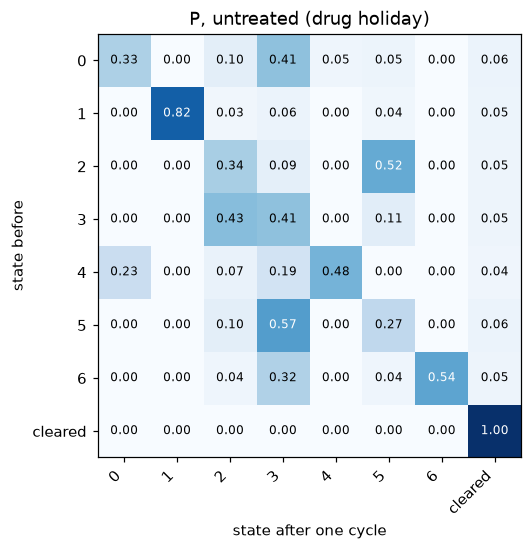

In [38]:
Phat_untr = transition_matrix(cells, "untreated")
P_untr = Phat_untr.to_numpy()
MATS["H"] = P_untr          # "H" = holiday: one cycle with no drug

show_matrix(Phat_untr, "P, untreated (drug holiday)")
plt.show()

<div class='alert alert-info'>
<b>Questions:</b>

1. Find the rows for `R_OSI` and `R_DOC` in the untreated matrix. Compare them
   with their rows under the drug each one survives. Where do resistant cells
   go during a break?
2. Look at the `cleared` column. How often do cells die with no drug?
</div>

*Answer here.*

### Does a break help?

Compare treatment plans of 16 cycles each. A letter is one cycle:
`O` osimertinib, `D` docetaxel, `H` a holiday (no drug). For example,
`"OOHH" * 4` is two cycles of osimertinib, two cycles off, four times over.

**Predict first:** for a tumor made only of `R_OSI` cells, which plan leaves
fewer survivors: osimertinib every cycle, or osimertinib with breaks?

In [39]:
HOLIDAY_PLANS = {
    "osimertinib x16":            "O" * 16,
    "(O, O, O, break) x4":        "OOOH" * 4,
    "(O, O, break, break) x4":    "OOHH" * 4,
    "osimertinib x8, then stop":  "O" * 8 + "H" * 8,
    "alternate O, D x16":         "OD" * 8,
    "(O, D, break, break) x4":    "ODHH" * 4,
}
tumors = {"measured mix": pi_mix,
          f"all cluster {R_OSI}": basis(R_OSI, P_hat),
          f"all cluster {BIG}": basis(BIG, P_hat)}
holiday_table = pd.DataFrame({t: {name: N_CELLS * (1 - run_schedule(pi0, plan)[-1])
                                  for name, plan in HOLIDAY_PLANS.items()}
                              for t, pi0 in tumors.items()})
print(f"expected surviving cells of {N_CELLS} (matrix, no division):")
holiday_table.round(3)

expected surviving cells of 100 (matrix, no division):


,measured mix,all cluster 1,all cluster 3
osimertinib x16,9.318,100.000,0.020
"(O, O, O, break) x4",4.957,52.769,0.056
"(O, O, break, break) x4",2.830,28.868,0.160
"osimertinib x8, then stop",6.677,65.117,0.708
"alternate O, D x16",0.014,0.006,0.016
"(O, D, break, break) x4",0.167,0.114,0.166


<div class='alert alert-info'>
<b>Questions:</b>

1. Which plans do better with breaks, and for which tumor? Use the untreated
   row of `R_OSI` to explain why a break can make osimertinib work *better*
   afterwards. (Biologists call this **re-sensitization**.)
2. For the tumor made only of cluster `BIG`, breaks make things slightly
   worse. Why?
3. Look at "osimertinib x8, then stop". In this model, what happens to the
   tumor during the eight cycles with no drug? Can the number of cells ever
   go *up*? Is that realistic, and what is the model missing?
</div>

*Answer here.*

## 8 · Reflection: which assumptions did we make?

Every forecast above rests on assumptions. For each one, say whether you think
it is reasonable for a real tumor and what would break if it were false.

1. **The states are right.** Every misclustered cell is a miscounted
   transition. What happens to $\hat P$ if you set `K = 6` and two of the
   sensitive states merge? Which conclusions survive?
2. **The Markov property.** A cell's next state depends only on its current
   state, not on how it got there. (The real PC9 data tests this one, and it
   fails.)
3. **Time-homogeneity.** We applied the *same* $P$ every cycle, estimated from
   one cycle. Tumors adapt; would cycle 10 look like cycle 1?
4. **One cell in, at most one cell out.** Real cells divide, so one tag at A
   can show up as many cells at B, and resistant survivors *regrow* the
   tumor. How would you change the counting?
5. **Missing tag means dead.** What else could make a tag disappear between
   time points?
6. **Resistance only pre-exists.** In our model no sensitive cell or persister
   ever becomes `CP`. In the real PC9 data, cycling persisters *do* arise from
   persisters during treatment. Suppose each `P` cell became `CP` with
   probability 0.01 per cycle under osimertinib. Could osimertinib still cure
   an all-S-G1 tumor of 100 cells? Of $10^9$ cells? (Use the reasoning from
   the tumor simulation.)

## Instructor check: estimated vs. true matrices

In [40]:
# Instructor check: estimated vs. true matrices (needs the instructor/ folder next to this notebook)
import sys
sys.path.insert(0, "instructor")
import simulate_data as sd
from add_untreated_arm import UNTREATED_P

truth = pd.read_csv("instructor/cells_with_truth_holiday.csv")
true_name = pd.crosstab(cells.cluster, truth.true_state).idxmax(axis=1)   # cluster -> true state
order = [sd.STATES.index(true_name[s]) for s in STATES]
print("clusters:", dict(true_name))
for arm, P_est in [("osimertinib", P_osi), ("docetaxel", P_doc), ("untreated", P_untr)]:
    P_true = UNTREATED_P if arm == "untreated" else sd.TRUE_P[arm]
    P_true = P_true[order][:, order + [7]]
    print(f"{arm:>12}: max |P_hat - P_true| = {np.abs(P_est[:7] - P_true).max():.3f}")

clusters: {0: 'P', 1: 'C', 2: 'S-syn', 3: 'S-G1', 4: 'NC', 5: 'S-G2M', 6: 'MDR'}
 osimertinib: max |P_hat - P_true| = 0.033
   docetaxel: max |P_hat - P_true| = 0.052
   untreated: max |P_hat - P_true| = 0.031
